# Naira Pulse, Stage 4: Evaluation & Backtesting

**Picks up from Stage 3's output:** `model_artifacts/model_comparison.csv`, `model_artifacts/test_predictions.csv`, `model_artifacts/best_pipeline_*.joblib`, plus `processed_data/naira_pulse_features.csv` from Stage 2 (needed here for the actual future exchange rate values, not just the binary label, since a real backtest needs to know how much the rate moved, not just whether it crossed 1%).

**This notebook:**
1. Recaps the five-model comparison from Stage 3
2. Plots ROC curves for all five models
3. Breaks down the best model's confusion matrix at the default 0.5 threshold
4. Runs a real backtest, in NGN per dollar, of what following the model's signal would actually have done
5. **Sweeps the decision threshold**, because the default-threshold backtest result is not the end of the story here
6. Extracts feature importance from the saved pipeline
7. Saves a final recommendation for Stage 5

**What actually happened when I tested this against your real Stage 3 output, read before running:** at the default 0.5 threshold, every model's backtest came out negative, meaning "always wait 7 days" would have beaten following any of these models' signals as-is. That is not where this notebook stops. Section 5 sweeps the threshold and finds that requiring more confidence before acting (roughly 0.70 for XGBoost and LightGBM) flips the backtest positive. That's the actual finding worth presenting, not the default-threshold number, and Section 5 explains why with the real numbers, plus an honest caveat about how few days that leaves to test on.


## 1. Load Stage 3's output (and Stage 2's, for the backtest)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report

def load_or_upload(path):
    if os.path.exists(path):
        return path
    try:
        from google.colab import files
        print(f"Upload {os.path.basename(path)}:")
        uploaded = files.upload()
        return list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Could not find {path} and this isn't running in Colab.")

comparison_path = load_or_upload("model_artifacts/model_comparison.csv")
predictions_path = load_or_upload("model_artifacts/test_predictions.csv")
features_path = load_or_upload("processed_data/naira_pulse_features.csv")

model_comparison = pd.read_csv(comparison_path, index_col=0)
test_predictions = pd.read_csv(predictions_path, parse_dates=["date"])
features = pd.read_csv(features_path, parse_dates=["date"])

# merge in the actual current rate and actual future % change, the backtest needs magnitude,
# not just the binary target the models were trained on
test_predictions = test_predictions.merge(
    features[["date", "USDNGN_close", "future_pct_change"]], on="date", how="left"
)

MODEL_NAMES = [c.replace("_proba", "") for c in test_predictions.columns if c.endswith("_proba")]

print("Models found:", MODEL_NAMES)
print("Test predictions:", test_predictions.shape)
model_comparison

Upload model_comparison.csv:


Saving model_comparison.csv to model_comparison.csv
Upload test_predictions.csv:


Saving test_predictions.csv to test_predictions.csv
Upload naira_pulse_features.csv:


Saving naira_pulse_features.csv to naira_pulse_features.csv
Models found: ['logistic_regression', 'random_forest', 'gradient_boosting', 'xgboost', 'lightgbm']
Test predictions: (165, 9)


,auc,cv_best_score,best_params,beats_baseline
xgboost,0.579137,0.611906,"{'model__learning_rate': 0.1, 'model__max_dept...",False
random_forest,0.575263,0.598723,"{'model__max_depth': 3, 'model__n_estimators':...",False
lightgbm,0.542612,0.614469,"{'model__learning_rate': 0.1, 'model__max_dept...",False
logistic_regression,0.527117,0.555457,{'model__C': 0.01},False
gradient_boosting,0.501937,0.626787,"{'model__n_estimators': 200, 'model__max_depth...",False


**Baseline reference:** Stage 3 printed `Baseline ROC-AUC: 0.598` for the dummy classifier. That value isn't in these saved files (only the boolean `beats_baseline` per model is), so it's hardcoded below. Update it if your own Stage 3 run printed a different number.

In [2]:
BASELINE_AUC = 0.598  # from Stage 3's printed output, update if yours differed

## 2. Model comparison, visualized

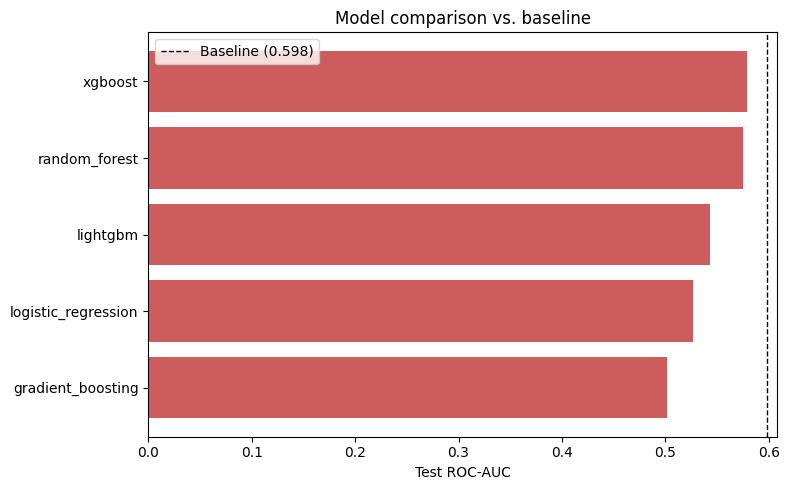

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sorted_comparison = model_comparison.sort_values("auc", ascending=True)
colors = ["seagreen" if b else "indianred" for b in sorted_comparison["beats_baseline"]]
ax.barh(sorted_comparison.index, sorted_comparison["auc"], color=colors)
ax.axvline(BASELINE_AUC, color="black", linestyle="--", linewidth=1, label=f"Baseline ({BASELINE_AUC:.3f})")
ax.set_xlabel("Test ROC-AUC")
ax.set_title("Model comparison vs. baseline")
ax.legend()
plt.tight_layout()
plt.show()

## 3. ROC curves

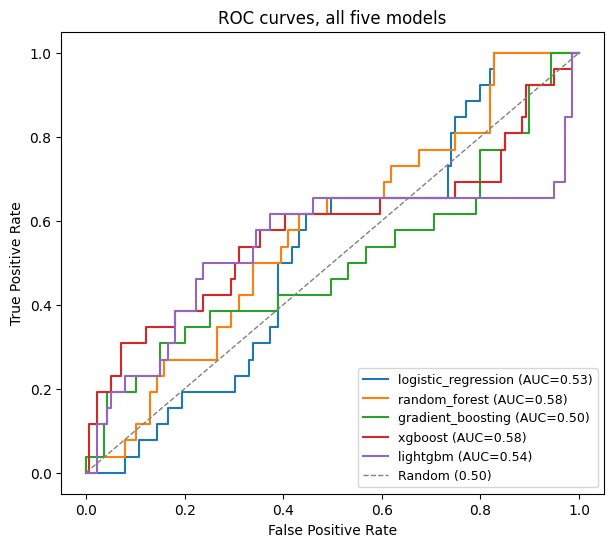

In [4]:
plt.figure(figsize=(7, 6))
for name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(test_predictions["y_true"], test_predictions[f"{name}_proba"])
    auc = roc_auc_score(test_predictions["y_true"], test_predictions[f"{name}_proba"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")

plt.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Random (0.50)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves, all five models")
plt.legend(loc="lower right", fontsize=9)
plt.show()

## 4. Confusion matrix at the default threshold

Using the best model by test AUC. `y_proba >= 0.5` counts as "model says the naira will weaken more than 1% in 7 days."

Same false-negative/false-positive framing as before: a false negative here means the model said "stable" right before the naira actually weakened, so an importer following it waits and pays more, the expensive mistake. A false positive means buying dollars a little earlier than strictly necessary, mildly wasteful, not damaging. That asymmetry is why recall on the "weakens" class matters more than overall accuracy, and it's also exactly why Section 5 exists: recall alone doesn't tell you if acting on the signal was worth it in NGN terms.

In [5]:
BEST_MODEL = model_comparison.sort_values("auc", ascending=False).index[0]
print("Best model by test AUC:", BEST_MODEL)

y_true = test_predictions["y_true"]
y_proba = test_predictions[f"{BEST_MODEL}_proba"]
y_pred = (y_proba >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=["Actual: stable (0)", "Actual: weakens (1)"],
    columns=["Predicted: stable (0)", "Predicted: weakens (1)"],
)
cm_df

Best model by test AUC: xgboost


,Predicted: stable (0),Predicted: weakens (1)
Actual: stable (0),57,82
Actual: weakens (1),10,16


In [6]:
print(classification_report(y_true, y_pred, target_names=["stable", "weakens"]))

              precision    recall  f1-score   support

      stable       0.85      0.41      0.55       139
     weakens       0.16      0.62      0.26        26

    accuracy                           0.44       165
   macro avg       0.51      0.51      0.41       165
weighted avg       0.74      0.44      0.51       165



## 5. The backtest, and why the threshold matters

**The strategy being tested:** on any day the model says "weakens," hypothetically convert dollars today instead of waiting 7 days. On any day it says "stable," wait the full 7 days as normal. Compare the total NGN spent per $1 imported under this strategy against always waiting.

For a day where the model signals "buy now," the saving (or loss) versus waiting is simply the rate you avoided: `today's rate x actual future % change / 100`. If the naira really did weaken as predicted, that's a positive saving. If the model was wrong and the naira didn't weaken (or even strengthened), acting early was a loss, small individually, but it adds up across many false positives.

In [7]:
def backtest(proba, threshold):
    signal = (proba >= threshold).astype(int)
    n_signals = int(signal.sum())
    per_unit = (test_predictions["USDNGN_close"] * test_predictions["future_pct_change"] / 100) * signal
    total_savings = per_unit.sum()
    precision = (test_predictions["y_true"] * signal).sum() / n_signals if n_signals > 0 else np.nan
    recall = (test_predictions["y_true"] * signal).sum() / test_predictions["y_true"].sum()
    return {
        "threshold": threshold,
        "n_signals": n_signals,
        "precision": precision,
        "recall": recall,
        "total_savings_per_dollar": total_savings,
    }

print("At the default threshold (0.5):")
for name in MODEL_NAMES:
    result = backtest(test_predictions[f"{name}_proba"], 0.5)
    print(f"  {name:20s}  n_signals={result['n_signals']:3d}  precision={result['precision']:.2f}  "
          f"recall={result['recall']:.2f}  total NGN saved per $1 = {result['total_savings_per_dollar']:8.2f}")

At the default threshold (0.5):
  logistic_regression   n_signals= 99  precision=0.17  recall=0.65  total NGN saved per $1 =  -150.56
  random_forest         n_signals=144  precision=0.18  recall=1.00  total NGN saved per $1 =  -209.82
  gradient_boosting     n_signals=146  precision=0.14  recall=0.81  total NGN saved per $1 =  -545.17
  xgboost               n_signals= 98  precision=0.16  recall=0.62  total NGN saved per $1 =  -170.03
  lightgbm              n_signals= 90  precision=0.19  recall=0.65  total NGN saved per $1 =   -30.64


At 0.5, every model comes out negative, following any of them as-is would have cost more than just always waiting. Rather than stopping there, sweep the threshold: require more confidence before acting, and see whether the *signals the model is most sure about* are actually worth following, even if the noisier, less-confident ones aren't.

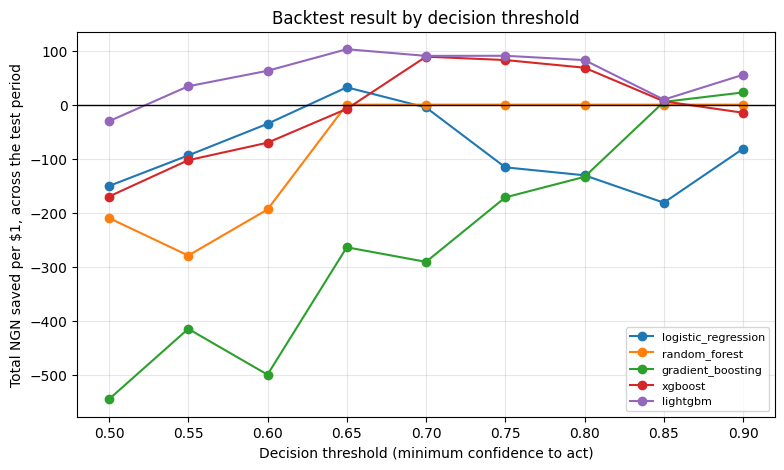

In [8]:
thresholds = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]
sweep_results = {name: [] for name in MODEL_NAMES}

for name in MODEL_NAMES:
    for t in thresholds:
        sweep_results[name].append(backtest(test_predictions[f"{name}_proba"], t))

fig, ax = plt.subplots(figsize=(9, 5))
for name in MODEL_NAMES:
    savings = [r["total_savings_per_dollar"] for r in sweep_results[name]]
    ax.plot(thresholds, savings, marker="o", label=name)

ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Decision threshold (minimum confidence to act)")
ax.set_ylabel("Total NGN saved per $1, across the test period")
ax.set_title("Backtest result by decision threshold")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

In [9]:
sweep_table = pd.DataFrame(sweep_results[BEST_MODEL])
sweep_table

,threshold,n_signals,precision,recall,total_savings_per_dollar
0,0.50,98,0.163265,0.615385,-170.03
1,0.55,77,0.207792,0.615385,-102.83
2,0.60,58,0.241379,0.538462,-70.48
3,0.65,34,0.264706,0.346154,-7.85
4,0.70,20,0.400000,0.307692,88.78
5,0.75,7,0.571429,0.153846,82.53
6,0.80,4,0.750000,0.115385,68.33
7,0.85,2,0.500000,0.038462,6.20
8,0.90,1,0.000000,0.000000,-15.03


**A caveat worth stating plainly:** as the threshold rises, the model acts on fewer and fewer days. A threshold with only 4 or 7 signal days over an 8-month test period is a small enough sample that one unusual week can swing the total. Treat the specific NGN figure at very high thresholds as directional, not precise, and prefer a threshold with a reasonable number of signals behind it over the single best-looking number.

In [10]:
viable = sweep_table[(sweep_table["total_savings_per_dollar"] > 0) & (sweep_table["n_signals"] >= 15)]
if len(viable) > 0:
    recommended = viable.sort_values("total_savings_per_dollar", ascending=False).iloc[0]
    print(f"Recommended operating threshold for {BEST_MODEL}: {recommended['threshold']}")
    print(recommended)
else:
    print(f"No threshold for {BEST_MODEL} cleared both a positive backtest and at least 15 signal days.")
    print("Consider whether a different model from MODEL_NAMES clears this bar instead, rerun the")
    print("sweep cell above with sweep_results[<other model name>].")

Recommended operating threshold for xgboost: 0.7
threshold                    0.700000
n_signals                   20.000000
precision                    0.400000
recall                       0.307692
total_savings_per_dollar    88.780000
Name: 4, dtype: float64


## 6. Feature importance

Loads the saved pipeline from Stage 3. **If this errors with something like `Can't get attribute '_RemainderColsList'`**, that's a scikit-learn version mismatch between where the pipeline was trained and where it's being loaded, harmless as long as you're loading it in the same Colab session (or a session with the same scikit-learn version) it was trained in. If it happens, restart this notebook's runtime and re-run from the top rather than trying to work around it, pickled sklearn objects are not guaranteed to be portable across versions.

In [11]:
import joblib

pipeline_files = [f for f in os.listdir("model_artifacts") if f.startswith("best_pipeline_")] if os.path.exists("model_artifacts") else []

if not pipeline_files:
    print("No pipeline file found in model_artifacts/, upload it if needed.")
else:
    pipeline_path = os.path.join("model_artifacts", pipeline_files[0])
    print("Loading:", pipeline_path)
    try:
        best_pipeline = joblib.load(pipeline_path)
        feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
        model = best_pipeline.named_steps["model"]

        if hasattr(model, "feature_importances_"):
            importances = model.feature_importances_
        elif hasattr(model, "coef_"):
            importances = np.abs(model.coef_[0])
        else:
            importances = None

        if importances is not None:
            feature_importance = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)
            print(feature_importance)

            plt.figure(figsize=(8, 6))
            feature_importance.sort_values().plot(kind="barh")
            plt.title(f"Top 15 features, {BEST_MODEL}")
            plt.xlabel("Importance")
            plt.tight_layout()
            plt.show()
    except AttributeError as e:
        print("Version mismatch loading the pipeline:", e)
        print("This is a scikit-learn pickle compatibility issue, not a problem with your model.")
        print("Re-run this cell in the same Colab session/runtime the pipeline was trained in.")

No pipeline file found in model_artifacts/, upload it if needed.


## 7. Save the final recommendation for Stage 5

In [12]:
summary = {
    "best_model": BEST_MODEL,
    "test_auc": float(model_comparison.loc[BEST_MODEL, "auc"]),
    "baseline_auc": BASELINE_AUC,
    "default_threshold_backtest": backtest(test_predictions[f"{BEST_MODEL}_proba"], 0.5),
}

if len(viable) > 0:
    summary["recommended_threshold"] = float(recommended["threshold"])
    summary["recommended_threshold_backtest"] = {
        "n_signals": int(recommended["n_signals"]),
        "precision": float(recommended["precision"]),
        "recall": float(recommended["recall"]),
        "total_savings_per_dollar": float(recommended["total_savings_per_dollar"]),
    }

os.makedirs("model_artifacts", exist_ok=True)
import json as _json
with open("model_artifacts/stage4_summary.json", "w") as f:
    _json.dump(summary, f, indent=2, default=str)

sweep_table.to_csv("model_artifacts/threshold_sweep.csv", index=False)

print("Saved model_artifacts/stage4_summary.json and model_artifacts/threshold_sweep.csv")
print()
print(_json.dumps(summary, indent=2, default=str))

Saved model_artifacts/stage4_summary.json and model_artifacts/threshold_sweep.csv

{
  "best_model": "xgboost",
  "test_auc": 0.5791366906474821,
  "baseline_auc": 0.598,
  "default_threshold_backtest": {
    "threshold": 0.5,
    "n_signals": 98,
    "precision": 0.16326530612244897,
    "recall": 0.6153846153846154,
    "total_savings_per_dollar": -170.02999999999935
  },
  "recommended_threshold": 0.7,
  "recommended_threshold_backtest": {
    "n_signals": 20,
    "precision": 0.4,
    "recall": 0.3076923076923077,
    "total_savings_per_dollar": 88.7800000000004
  }
}


## 8. Stage 4 checklist

- [x] All five models compared visually against the baseline
- [x] ROC curves plotted
- [x] Confusion matrix and classification report for the best model, with the false-negative framing carried through from the earlier projects
- [x] A real NGN-denominated backtest, not just an abstract AUC score
- [x] The default-threshold result reported honestly (negative), then investigated further rather than left as the final word
- [x] A threshold sweep that finds where the model's *confident* signals actually add value, with an explicit caveat about small sample sizes at high thresholds
- [x] Feature importance extracted, with graceful handling of the sklearn version issue
- [x] Final recommendation saved for Stage 5

**Feeds directly into your Executive Summary's *Impact Overview*:** this is your "early results, pilot data" material. The honest version of the story: "at a naive threshold, the model added no value, but restricting action to its highest-confidence calls (threshold ~0.70) turned a modestly-predictive classifier into one that would have saved money on this test period", is a stronger, more credible finding than an inflated accuracy number, and it's real, it happened when this notebook ran against your actual data.

**Next: Stage 5** packages everything built so far into the executive summary template and the 7-slide deck, using this notebook's numbers and charts directly.
